<img src="../res/logo.jpg" alt="Volcanicus" width="50%">

# Scenes

A **scene** is everything observed on a single date: a grid of every direction x every distance bin. Scenes are the natural sample unit for a model, so `Volcano` can reshape its (long, one row per date/direction) data into one row per scene.

This notebook covers `to_scenes()`, `reduce_directions()` and the `scenes_median` / `scenes_max` shortcuts. See [tutorial.ipynb](tutorial.ipynb) first if you haven't yet — it covers the `Volcano` API this notebook assumes you already know.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

import volcanicus

volcano = volcanicus.datasets.load("copahue")
volcano

dates,106
missing,3086
registers,848


## One row per scene

`to_scenes()` returns a `DataFrame` indexed by `date`, with two-level columns `(direction, distance)`.

The grid is always complete: directions follow `DIRECTION_ORDER` and any date/direction pair missing from the source data is filled with `NaN`, so every scene has exactly the same shape no matter the volcano.

In [2]:
scenes = volcano.to_scenes()
print(scenes.shape)
scenes.iloc[:5, :6]

(106, 240)


direction        N                                        
distance       15m     45m     75m    105m    135m    165m
date                                                      
2000-12-05  0.3021  0.2859  0.3275  0.3446  0.3645  0.3823
2000-12-12  0.2852  0.1733  0.2028  0.1393  0.1630  0.1454
2001-04-12     NaN -0.0190 -0.0775 -0.1012 -0.1322 -0.1275
2002-01-16     NaN -0.0302 -0.1427 -0.1469 -0.1558 -0.0388
2005-04-23     NaN  0.0100  0.0180  0.0164  0.0172  0.0163

Selecting a direction (or a single date) works with the usual `pandas` indexing:

In [3]:
scenes["NE"].iloc[:5, :5]

distance,15m,45m,75m,105m,135m
date,,,,,
2000-12-05,NaN,0.2296,0.2058,-0.0006,-0.1171
2000-12-12,NaN,0.1534,0.0593,-0.1615,-0.2498
2001-04-12,NaN,0.0619,0.0080,-0.0386,-0.0884
2002-01-16,NaN,0.0602,0.0374,0.0258,0.0417
2005-04-23,NaN,0.0107,0.0036,-0.0098,0.0160


## As a 3-D array

With `as_array=True` you get the same values as a `numpy.ndarray` of shape `(n_dates, n_directions, n_distances)`: axis 0 follows the sorted dates, axis 1 follows `DIRECTION_ORDER` and axis 2 the distance bins. This is the shape most models expect.

In [4]:
cube = volcano.to_scenes(as_array=True)
print(cube.shape)
print(f"missing: {np.isnan(cube).mean():.1%}")

(106, 8, 30)
missing: 12.1%


## Looking at a single scene

Each scene is a small direction x distance image.

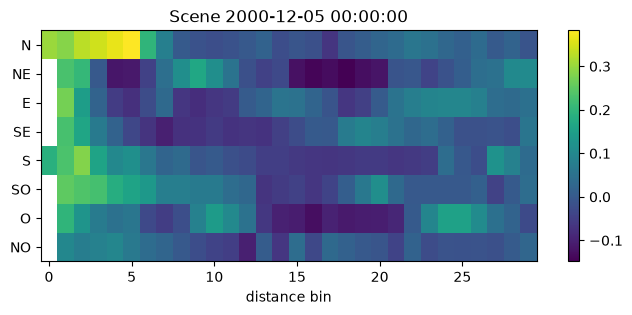

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
im = ax.imshow(cube[0], aspect="auto")
ax.set_yticks(range(cube.shape[1]), scenes.columns.get_level_values("direction").unique())
ax.set_xlabel("distance bin")
ax.set_title(f"Scene {scenes.index[0]}")
fig.colorbar(im, ax=ax)

## Collapsing the directions

`reduce_directions(how)` reduces the 8 directions at every distance, leaving one radial profile per date (`DataFrame` indexed by `date`, one column per distance bin). `NaN` values are skipped, so a missing direction doesn't spoil the others.

`how` is one of `"count"`, `"max"`, `"mean"`, `"median"` (default), `"min"`, `"std"`, `"sum"` or `"var"`; anything else raises `ValueError`.

In [6]:
volcano.reduce_directions("mean").iloc[:5, :5]

distance,15m,45m,75m,105m,135m
date,,,,,
2000-12-05,0.245650,0.223963,0.195687,0.121738,0.079763
2000-12-12,0.254700,0.182286,0.144271,0.041786,0.007286
2001-04-12,0.144100,0.095600,0.078500,0.053250,0.028050
2002-01-16,0.056167,0.034912,0.000813,-0.017337,-0.019600
2005-04-23,0.021000,0.029125,0.021675,0.015787,0.018275


Two reductions are available as properties: `scenes_median` is the typical profile (a single anomalous direction doesn't drag it) and `scenes_max` is the hottest direction.

In [7]:
volcano.scenes_median.iloc[:5, :5]

distance,15m,45m,75m,105m,135m
date,,,,,
2000-12-05,0.24565,0.23030,0.18440,0.07870,0.07275
2000-12-12,0.28520,0.17330,0.15800,0.05000,0.04670
2001-04-12,0.10130,0.08930,0.07635,0.05635,0.04235
2002-01-16,0.04470,0.03660,0.03015,0.00000,-0.01695
2005-04-23,0.01220,0.01275,0.02055,0.01735,0.01660


In [8]:
volcano.scenes_max.iloc[:5, :5]

distance,15m,45m,75m,105m,135m
date,,,,,
2000-12-05,0.3021,0.2859,0.3275,0.3446,0.3645
2000-12-12,0.2899,0.2321,0.2143,0.1393,0.1630
2001-04-12,0.2471,0.2417,0.2415,0.2062,0.1399
2002-01-16,0.0817,0.0733,0.0523,0.0390,0.0501
2005-04-23,0.0504,0.1211,0.0795,0.0596,0.0588


Comparing both for one date shows how far the hottest direction sits above the typical one:

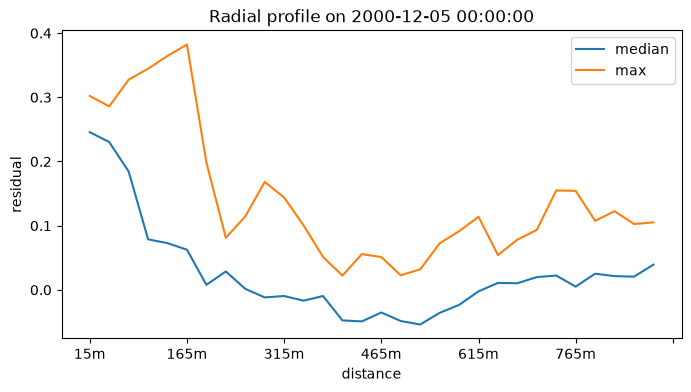

In [9]:
date = volcano.scenes_median.index[0]

fig, ax = plt.subplots(figsize=(8, 4))
volcano.scenes_median.loc[date].plot(ax=ax, label="median")
volcano.scenes_max.loc[date].plot(ax=ax, label="max")
ax.set_title(f"Radial profile on {date}")
ax.set_ylabel("residual")
ax.legend()

## Next steps

- [tutorial.ipynb](tutorial.ipynb) for the full `Volcano` API walkthrough.
- [comparison.ipynb](comparison.ipynb) to compare several volcanoes side by side.
- [README.md](../README.md) for installation and a quick reference.